- 모델을 GAN, 이미지 생성 모델로 할거임
- GAN은 학습에 사용할 이미지들이 어떤 특징을 가지고 있고, 생성자가 어떤 이미지를 학습해야 하는지 확인하는 것이 중요
- 학습 데이터의 특징을 학습한 후, 학습 데이터와 비슷하지만 다른 새로운 이미지 생성 가능
- 생성자 : 가짜 이미지를 진짜처럼 생성 / 판별자 : 입력 이미지가 진짜인지 가짜인지 판별 - 두개가 서로 경쟁하며 학습
- 이미지마다 정답 라벨이 없어도 학습 가능
- 실제 이미지와 생성된 이미지를 구분하는 과정에서 학습하기 때문
- 생성자와 판별자의 학습 균형이 무너지지 않게 해야함
- 무너지면 이미지 품질이 좋아지지 않거나 비슷한 이미지만 생성됨

In [2]:
import os
import torch
from torchvision import datasets, transforms

# 1. 데이터 경로 설정
path = "./data"

# 2. 데이터셋 불러오기
transform = transforms.ToTensor()

# 학습 데이터
train_dataset = datasets.FashionMNIST(
    root=path,
    train=True,
    download=True,
    transform=transform
)

# 테스트 데이터
test_dataset = datasets.FashionMNIST(
    root=path,
    train=False,
    download=True,
    transform=transform
)

# 3. 데이터 기본 정보 확인
print("데이터 경로:", os.path.abspath(path))
print("경로 존재 여부:", os.path.exists(path))
print("전체 학습 이미지 수:", len(train_dataset))
print("전체 테스트 이미지 수:", len(test_dataset))

# 4. 첫 번째 학습 이미지 확인
image, label = train_dataset[0]

print("이미지 형태:", image.shape)
print("이미지 자료형:", image.dtype)
print("픽셀 최솟값:", image.min().item())
print("픽셀 최댓값:", image.max().item())
print("라벨:", label)

# 5. 전체 데이터의 이미지 형태 확인
print("이미지 크기:", train_dataset[0][0].shape)


100%|██████████| 26.4M/26.4M [00:06<00:00, 4.23MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 109kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.65MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 63.5MB/s]

데이터 경로: c:\AI\pytorch\FashionMNIST\data
경로 존재 여부: True
전체 학습 이미지 수: 60000
전체 테스트 이미지 수: 10000
이미지 형태: torch.Size([1, 28, 28])
이미지 자료형: torch.float32
픽셀 최솟값: 0.0
픽셀 최댓값: 1.0
라벨: 9
이미지 크기: torch.Size([1, 28, 28])


- 경로로 잘 불러오는지 확인됨
- 전체 학습/테스트 이미지 수 파악 가능
- 일단 이 이미지 형태는 흑백(채널1), 높이 28, 너비 28임 / 나중에 모든 이미지의 형태도 파악해봐야할듯
- 자료형에서 float32임. 32비트 실수형임. 픽셀값이 대부분 0~1 범위라 소수점이 사용 가능하도록 함
- 최소0 ~ 최대1 : 픽셀값 범위임
- 라벨 9임 / 클래스가 뭔지 확인을 아직 안했음 뒤에서 확인해보고 다시 돌아와도될듯 - 앵클부츠라고함

## 클래스별 이미지 수 확인

In [3]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

class_counts = [0] * 10

for image, label in train_dataset:
    class_counts[label] += 1

for i, name in enumerate(class_names):
    print(f"클래스 {i} ({name}): {class_counts[i]}장")

클래스 0 (T-shirt/top): 6000장
클래스 1 (Trouser): 6000장
클래스 2 (Pullover): 6000장
클래스 3 (Dress): 6000장
클래스 4 (Coat): 6000장
클래스 5 (Sandal): 6000장
클래스 6 (Shirt): 6000장
클래스 7 (Sneaker): 6000장
클래스 8 (Bag): 6000장
클래스 9 (Ankle boot): 6000장


- 클래스별로 어떤 종류인지와 클래스 번호를 확인했음
- 그리고 각 클래스마다 몇장의 이미지가 있는지 확인됨
- (위에서 확인한 라벨 9가 뭔지도 알게됨)

## 이미지 크기 확인

In [4]:
from collections import Counter

# 이미지 크기별 개수를 저장할 변수
image_sizes = Counter()

# 전체 학습 이미지 확인
for image, label in train_dataset:
    # image.shape: (채널, 높이, 너비)
    channels, height, width = image.shape

    # 가로, 세로 크기를 저장
    image_sizes[(width, height)] += 1

print("이미지 크기별 개수")

for size, count in image_sizes.items():
    print(f"가로·세로 크기 {size}: {count}장")

이미지 크기별 개수
가로·세로 크기 (28, 28): 60000장


- 아까 한장의 이미지 크기를 확인했었음
- 전체의 이미지 크기는 어떻게 되어있는지 확인함
- 편하게 모든 이미지가 28x28 로 같은 크기임 굿임
- 이런 미션은 처음이라 전처리 과정에서 resize 를 안해도되는건지 궁금증이듬

## 채널 확인

In [5]:
from collections import Counter

# 채널별 이미지 개수 저장
channel_counts = Counter()

for image, label in train_dataset:
    # 이미지 형태: (채널, 높이, 너비)
    channels = image.shape[0]

    channel_counts[channels] += 1

print("채널별 이미지 개수")

for channels, count in channel_counts.items():
    if channels == 1:
        name = "흑백 이미지"
    elif channels == 3:
        name = "RGB 이미지"
    elif channels == 4:
        name = "RGBA 이미지"
    else:
        name = "기타"

    print(f"{name} ({channels}채널): {count}장")

채널별 이미지 개수
흑백 이미지 (1채널): 60000장


- 아까 채널도 흑백이었음
- 전체 이미지의 채널도 같은지 확인해봄
- 위에 크기와 같이 채널도 모두 1임
- 모든 이미지가 (1, 28, 28) 임

## 이상/손상/중복 이미지 확인

In [6]:
import torch
import hashlib
from collections import Counter
from PIL import Image

# 검사 결과 저장
invalid_images = []
abnormal_images = []
image_hashes = {}

# 1. 전체 이미지 검사
for idx in range(len(train_dataset)):
    try:
        image, label = train_dataset[idx]

        # 이미지와 라벨의 기본 정보 확인
        if not isinstance(image, torch.Tensor):
            invalid_images.append((idx, "이미지가 텐서가 아님"))
            continue

        if image.shape != (1, 28, 28):
            invalid_images.append((idx, f"잘못된 이미지 크기: {image.shape}"))
            continue

        if not torch.isfinite(image).all():
            invalid_images.append((idx, "NaN 또는 무한대 픽셀값"))
            continue

        # 픽셀값이 모두 같은 이미지 확인
        if image.min() == image.max():
            abnormal_images.append((idx, "모든 픽셀값이 동일함"))

        # 라벨 범위 확인
        label = int(label)
        if label < 0 or label > 9:
            invalid_images.append((idx, f"잘못된 라벨: {label}"))
            continue

        # 2. 픽셀값이 완전히 같은 중복 이미지 확인
        image_bytes = image.contiguous().numpy().tobytes()
        image_hash = hashlib.md5(image_bytes).hexdigest()

        if image_hash in image_hashes:
            image_hashes[image_hash].append(idx)
        else:
            image_hashes[image_hash] = [idx]

    except Exception as e:
        invalid_images.append((idx, str(e)))

# 3. 중복 이미지 목록 정리
duplicate_groups = [
    indices
    for indices in image_hashes.values()
    if len(indices) > 1
]

duplicate_count = sum(
    len(indices) - 1 for indices in duplicate_groups
)

# 4. 검사 결과 출력
print("===== 데이터 검사 결과 =====")
print("전체 이미지 수:", len(train_dataset))
print("손상 또는 형식 이상 이미지 수:", len(invalid_images))
print("단색 이미지 수:", len(abnormal_images))
print("중복 이미지 그룹 수:", len(duplicate_groups))
print("중복으로 추가 확인된 이미지 수:", duplicate_count)

# 5. 발견된 항목 출력
print("\n[손상 또는 형식 이상 이미지]")
print(invalid_images[:20] if invalid_images else "발견되지 않음")

print("\n[단색 이미지]")
print(abnormal_images[:20] if abnormal_images else "발견되지 않음")

print("\n[중복 이미지 그룹]")
print(duplicate_groups[:20] if duplicate_groups else "발견되지 않음")


===== 데이터 검사 결과 =====
전체 이미지 수: 60000
손상 또는 형식 이상 이미지 수: 0
단색 이미지 수: 0
중복 이미지 그룹 수: 0
중복으로 추가 확인된 이미지 수: 0

[손상 또는 형식 이상 이미지]
발견되지 않음

[단색 이미지]
발견되지 않음

[중복 이미지 그룹]
발견되지 않음


- DAN은 학습할 이미지가 중요하다고 해서 손상된거나 중복, 이상한것들이 있는지 확인했음
- 다행이 학습 60000장 중에 못쓸것은 없는거같음
- 거를거 없이 바로 학습에 들어가도됨

## 픽셀 확인

픽셀 최솟값: 0.0
픽셀 최댓값: 1.0
전체 평균 밝기: 0.28604060299881057


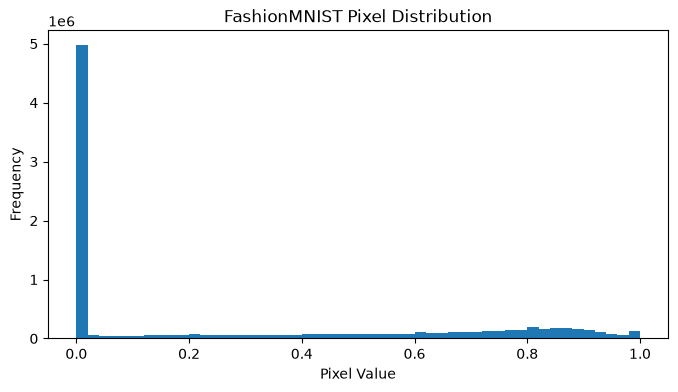

In [7]:
import matplotlib.pyplot as plt
import torch

# 전체 학습 이미지의 픽셀 값 합계와 개수
pixel_sum = 0
pixel_count = 0

# 픽셀 분포를 확인하기 위한 데이터
all_pixels = []

for image, label in train_dataset:
    pixels = image.flatten()

    pixel_sum += pixels.sum().item()
    pixel_count += pixels.numel()

    # 그래프 계산량을 줄이기 위해 일부 픽셀만 저장
    all_pixels.extend(pixels[::5].tolist())

# 전체 평균 밝기
mean_brightness = pixel_sum / pixel_count

print("픽셀 최솟값:", min(all_pixels))
print("픽셀 최댓값:", max(all_pixels))
print("전체 평균 밝기:", mean_brightness)

# 픽셀 분포 그래프
plt.figure(figsize=(8, 4))
plt.hist(all_pixels, bins=50)
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.title("FashionMNIST Pixel Distribution")
plt.show()

- 이미지들의 밝기를 찾아봄
- 이미지의 대부분이 검은색인거같음
- 평균이 0.3 도 안됨 전체적으로 어두운색으로 되어있음
- 의류니까 아마 배경?이 어두운색으로 되어있을거같음
- 이미지를 봐야할거같음

## 이미지 시각화

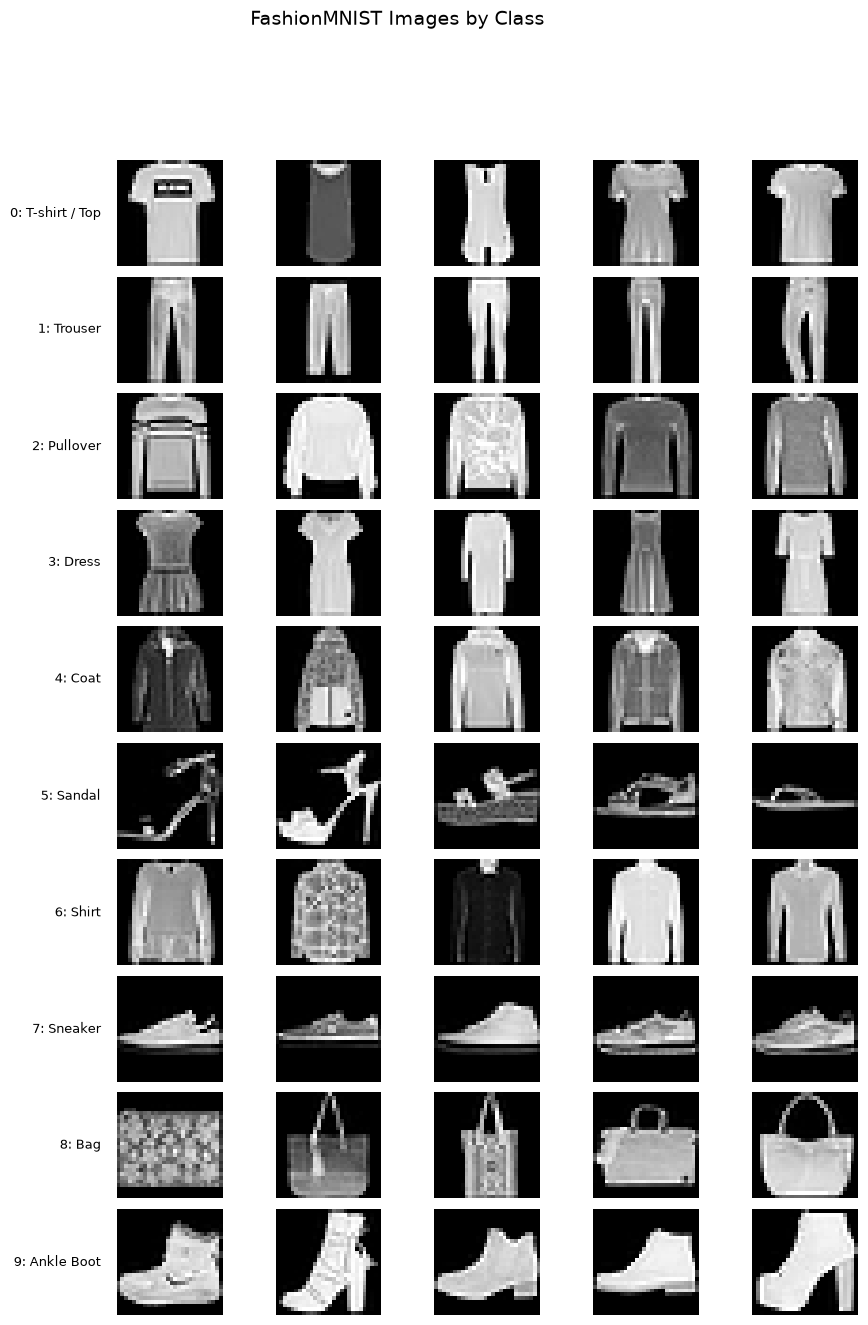

In [21]:

import matplotlib.pyplot as plt

num_images = 5

# 왼쪽에 클래스 이름을 표시할 공간 확보
fig, axes = plt.subplots(10, num_images, figsize=(12, 15))

for class_id in range(10):

    # 클래스별 이미지 5장 출력
    for j in range(num_images):
        image = samples_by_class[class_id][j]

        axes[class_id, j].imshow(image.squeeze(), cmap="gray")
        axes[class_id, j].axis("off")

    # 각 행의 첫 번째 이미지 왼쪽에 클래스 이름 표시
    axes[class_id, 0].text(
        -0.15, 0.5,
        f"{class_id}: {class_names[class_id]}",
        transform=axes[class_id, 0].transAxes,
        ha="right",
        va="center",
        fontsize=9,
        clip_on=False
    )

# 왼쪽 여백을 넉넉하게 확보
plt.subplots_adjust(left=0.25, wspace=0.1, hspace=0.1)
plt.suptitle("FashionMNIST Images by Class", fontsize=14)
plt.show()


- 위에서 찾아본것들을 확인하기 위해 시각화해봄
- 생각한대로 배경이 검은색이라서 평균 밝기가 낮았던거임
- 크기도 같고 채널도 같음

## 히트맵 확인

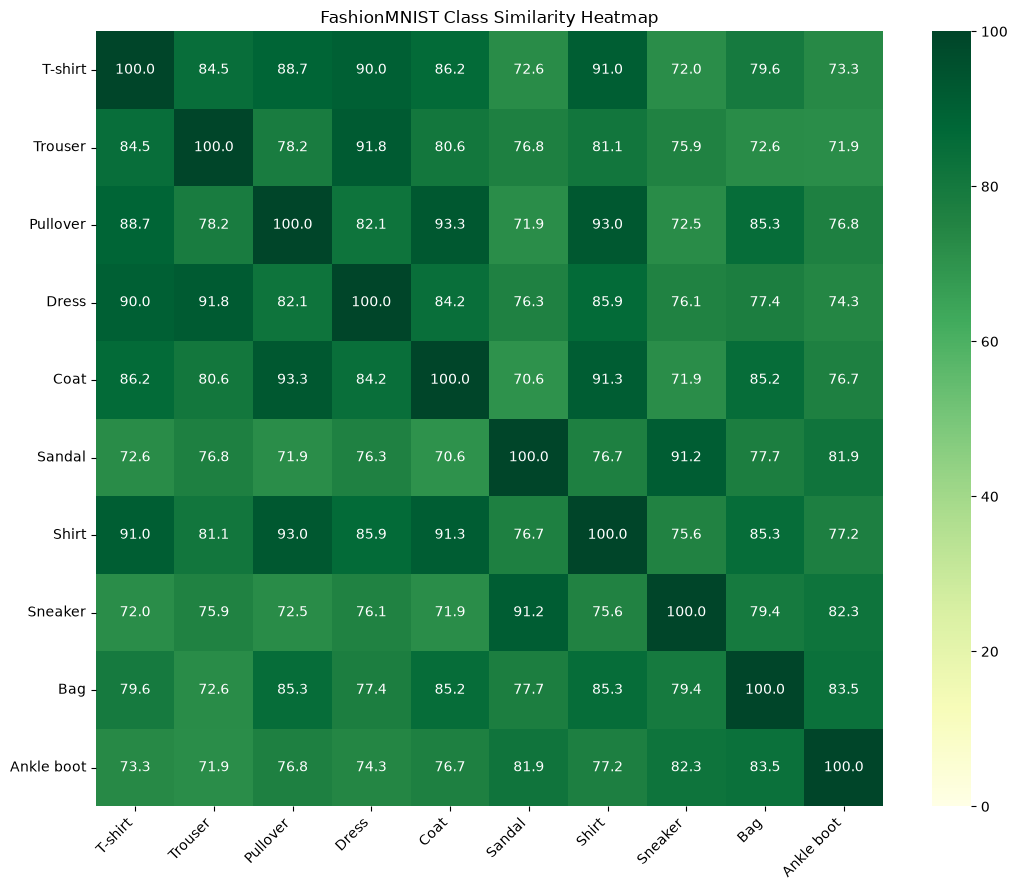

In [58]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import random

class_names = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

random.seed(42)

# 클래스별 이미지 인덱스 수집
class_indices = {i: [] for i in range(10)}

for i in range(len(train_dataset)):
    _, label = train_dataset[i]
    class_indices[int(label)].append(i)

# 클래스별 평균 이미지 계산
mean_images = []

for class_id in range(10):
    # 클래스마다 최대 500장 무작위 추출
    indices = random.sample(
        class_indices[class_id],
        min(500, len(class_indices[class_id]))
    )

    images = torch.stack([
        train_dataset[i][0].float()
        for i in indices
    ])

    # 이미지 픽셀의 평균 계산
    mean_image = images.mean(dim=0)
    mean_images.append(mean_image)

# 클래스 평균 이미지끼리 픽셀 유사도 계산
similarity_matrix = torch.zeros(10, 10)

for i in range(10):
    for j in range(10):
        # 정규화된 픽셀 범위를 0~1로 변환
        image_a = (mean_images[i] + 1) / 2
        image_b = (mean_images[j] + 1) / 2

        mae = torch.mean(torch.abs(image_a - image_b)).item()

        # 픽셀 차이를 간단한 유사도(%)로 변환
        similarity_matrix[i, j] = (1 - mae) * 100

# 히트맵 시각화
plt.figure(figsize=(11, 9))

sns.heatmap(
    similarity_matrix.numpy(),
    annot=True,
    fmt=".1f",
    cmap="YlGn",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=100
)

plt.title("FashionMNIST Class Similarity Heatmap")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

- 히트맵을 통해서 각 클래스마다 유사도를 확인할 수 있음

## 학습/테스트 데이터 중복 확인

In [22]:
# 학습 데이터와 테스트 데이터의 이미지 중복 확인

# 1. 학습 데이터의 이미지 정보를 저장
train_images = set()

for image, label in train_dataset:
    # 이미지 텐서를 바이트 데이터로 변환
    image_data = image.numpy().tobytes()

    # 학습 이미지 정보를 집합에 저장
    train_images.add(image_data)


# 2. 테스트 데이터와 학습 데이터 비교
duplicate_count = 0

for image, label in test_dataset:
    # 테스트 이미지를 바이트 데이터로 변환
    image_data = image.numpy().tobytes()

    # 학습 데이터에 동일한 이미지가 있는지 확인
    if image_data in train_images:
        duplicate_count += 1


# 3. 결과 출력
print("학습 데이터 이미지 수:", len(train_dataset))
print("테스트 데이터 이미지 수:", len(test_dataset))
print("학습·테스트 데이터 중복 이미지 수:", duplicate_count)

학습 데이터 이미지 수: 60000
테스트 데이터 이미지 수: 10000
학습·테스트 데이터 중복 이미지 수: 0


- 모델 만들고 학습 하기전에 학습과 테스트 데이터가 중복되는게 없는지 한번 더 확인함

## 학습/검증/테스트 분리

In [23]:
from torch.utils.data import random_split

# 재현 가능한 데이터 분할을 위한 시드 설정
generator = torch.Generator().manual_seed(42)

# 학습 데이터 90%, 검증 데이터 10%로 분리
train_size = int(len(train_dataset) * 0.9)
val_size = len(train_dataset) - train_size

train_dataset, val_dataset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=generator
)

# 분할 결과 확인
print("학습 데이터 수:", len(train_dataset))
print("검증 데이터 수:", len(val_dataset))
print("테스트 데이터 수:", len(test_dataset))

학습 데이터 수: 54000
검증 데이터 수: 6000
테스트 데이터 수: 10000


- 학습이랑 테스트만 있어서 검증을 분리해봄
- 베이스라인과 코드잇 미션에도 학습이랑 테스트밖에 없어서 안해도되는건지는 잘 모름
- 일단 하던거니까 해봄

- 일단 필요하다고 생각한건 간단하게 다 찾아봄
- 학습해서 이상하다 싶으면 또 돌아와서 채우는걸로

## 데이터 전처리

In [27]:

import os
import torch
from torchvision import datasets, transforms

# 1. 데이터 저장 경로
path = "./data"

# 2. 이미지 전처리 설정
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# 3. 학습 데이터 불러오기
train_dataset = datasets.FashionMNIST(
    root=path,
    train=True,
    download=True,
    transform=transform
)

# 4. 테스트 데이터 불러오기
test_dataset = datasets.FashionMNIST(
    root=path,
    train=False,
    download=True,
    transform=transform
)

# 5. 전처리 결과 확인
image, label = train_dataset[0]

print("학습 데이터 수:", len(train_dataset))
print("테스트 데이터 수:", len(test_dataset))
print("이미지 형태:", image.shape)
print("이미지 자료형:", image.dtype)
print("픽셀 최솟값:", image.min().item())
print("픽셀 최댓값:", image.max().item())
print("라벨:", label)


학습 데이터 수: 60000
테스트 데이터 수: 10000
이미지 형태: torch.Size([1, 28, 28])
이미지 자료형: torch.float32
픽셀 최솟값: -1.0
픽셀 최댓값: 1.0
라벨: 9


- normalize 만 사용해 이미지 픽셀 값을 -1~1 로 맞추는 전처리만 함
- (생성자 마지막 출력층에 Tanh() 를 사용해 생성 이미지의 범위를 -1~1로 맞추기 위함이라고 함)
- 이미지 크기는 전부 같고 RGB 변환도 필요없음 (전부 흑색 - 채널 1)
- 회전이나 반전 등 데이터 증강도 의류 형태를 바꿀거같아서 따로 안함
- 따라서 텐서 변환과 픽셀값 변환만 함

In [32]:
import torch
import torch.nn as nn

# 생성자 모델
class Generator(nn.Module):

    def __init(self, noise_dim=100, num_classes=10, embed_dim=10):
        super().__init()

        # 클래스 라벨을 임베딩 벡터로 변환
        self.label.embedding = nn.Embedding(num_classes, embed_dim)

        # 노이즈와 라벨 정보를 이용해 이미지 생성
        self.model = nn.Sequential(nn.Linear(noise_dim + embed_dim, 256),
                                   nn.ReLU(),
                                   
                                   nn.Linear(256, 512),
                                   nn.ReLU(),
                                   
                                   nn.Linear(512, 1024),
                                   nn.ReLU(),
                                   
                                   nn.Linear(1024, 28 * 28),
                                   nn.Tanh())

    def forward(self, noise, labels):

        # 라벨을 벡터로 변환
        label_vector = self.label_embedding(labels)

        # 노이즈와 라벨 정보를 결합
        x = torch.cat((noise, label_vector), dim=1)

        # 이미지 생성
        image = self.model(x)

        # 1채널, 28x28 이미지 형태로 변경
        image = image.view(-1, 1, 28, 28)

        return image

In [35]:

import torch
import torch.nn as nn

# 1. 생성자 클래스 정의
class Generator(nn.Module):
    def __init__(self, noise_dim=100, num_classes=10, embed_dim=10):
        super().__init__()

        self.label_embedding = nn.Embedding(num_classes, embed_dim)

        self.model = nn.Sequential(
            nn.Linear(noise_dim + embed_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 1024),
            nn.ReLU(),
            nn.Linear(1024, 28 * 28),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        label_vector = self.label_embedding(labels)
        x = torch.cat((noise, label_vector), dim=1)
        image = self.model(x)
        image = image.view(-1, 1, 28, 28)
        return image


# 2. 새 생성자 객체 만들기
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
generator = Generator().to(device)

# 3. 테스트 데이터 만들기
noise = torch.randn(4, 100, device=device)
labels = torch.tensor([7, 8, 9, 3], device=device)

# 4. 이미지 생성 테스트
fake_images = generator(noise, labels)

print("모델 속성:", generator.__dict__.keys())
print("생성 이미지 형태:", fake_images.shape)
print("픽셀 최솟값:", fake_images.min().item())
print("픽셀 최댓값:", fake_images.max().item())


모델 속성: dict_keys(['training', '_parameters', '_buffers', '_non_persistent_buffers_set', '_backward_pre_hooks', '_backward_hooks', '_is_full_backward_hook', '_forward_hooks', '_forward_hooks_with_kwargs', '_forward_hooks_always_called', '_forward_pre_hooks', '_forward_pre_hooks_with_kwargs', '_state_dict_hooks', '_state_dict_pre_hooks', '_load_state_dict_pre_hooks', '_load_state_dict_post_hooks', '_modules'])
생성 이미지 형태: torch.Size([4, 1, 28, 28])
픽셀 최솟값: -0.16742829978466034
픽셀 최댓값: 0.14321862161159515


In [36]:

import torch
import torch.nn as nn

# 판별자 모델
class Discriminator(nn.Module):

    def __init__(self, num_classes=10, embed_dim=10):
        super().__init__()

        # 클래스 라벨을 벡터로 변환
        self.label_embedding = nn.Embedding(num_classes, embed_dim)

        # 이미지와 라벨을 이용해 진짜/가짜 판별
        self.model = nn.Sequential(
            nn.Linear(28 * 28 + embed_dim, 512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, 1)
        )

    def forward(self, image, labels):

        # 이미지의 배치 형태를 유지하면서 1차원으로 펼치기
        image = image.view(image.size(0), -1)

        # 라벨을 벡터로 변환
        label_vector = self.label_embedding(labels)

        # 이미지와 라벨 정보 결합
        x = torch.cat((image, label_vector), dim=1)

        # 진짜일 가능성에 대한 점수 출력
        output = self.model(x)

        return output


In [37]:

# 판별자 생성
discriminator = Discriminator().to(device)

# 생성자가 만든 가짜 이미지 생성
noise = torch.randn(4, 100, device=device)
labels = torch.tensor([7, 8, 9, 3], device=device)

fake_images = generator(noise, labels)

# 판별자가 가짜 이미지 평가
fake_scores = discriminator(fake_images, labels)

print("입력 이미지 형태:", fake_images.shape)
print("입력 라벨 형태:", labels.shape)
print("판별 결과 형태:", fake_scores.shape)
print("판별 점수:", fake_scores.detach().flatten())


입력 이미지 형태: torch.Size([4, 1, 28, 28])
입력 라벨 형태: torch.Size([4])
판별 결과 형태: torch.Size([4, 1])
판별 점수: tensor([0.0228, 0.0284, 0.0276, 0.0389], device='cuda:0')


In [38]:

import torch.nn as nn
import torch.optim as optim

# 1. 손실 함수 설정
criterion = nn.BCEWithLogitsLoss()

# 2. 생성자 옵티마이저 설정
optimizer_G = optim.Adam(
    generator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

# 3. 판별자 옵티마이저 설정
optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

print("손실 함수:", criterion)
print("생성자 옵티마이저:", optimizer_G)
print("판별자 옵티마이저:", optimizer_D)


손실 함수: BCEWithLogitsLoss()
생성자 옵티마이저: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.5, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0002
    maximize: False
    weight_decay: 0
)
판별자 옵티마이저: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.5, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0002
    maximize: False
    weight_decay: 0
)


- 생성자와 판별자 두 모델은 서로 다른 목표를 가지고 학습해서 각각 별도의 옵티마이저가 필요하다네
- 다른 의미로 학습해서 출력이 뭔가 다를거같았지만 같음

## 학습

In [51]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

# ==========================================
# 1. 학습 설정
# ==========================================

batch_size = 128
noise_dim = 100
num_epochs = 30

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

# 모델 초기화
generator = Generator().to(device)
discriminator = Discriminator().to(device)

# 손실 함수
criterion = nn.BCEWithLogitsLoss()

# 옵티마이저
optimizer_G = optim.Adam(
    generator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

# 비교할 학습 구간
compare_epochs = [1, 5, 10, 20, 30]

# 동일한 노이즈와 라벨로 구간별 결과 비교
torch.manual_seed(42)

fixed_noise = torch.randn(
    10, noise_dim, device=device
)

fixed_labels = torch.arange(10, device=device)

# 구간별 생성 이미지 저장
generated_images_by_epoch = {}

# 에포크별 Loss 저장
loss_D_history = []
loss_G_history = []


# ==========================================
# 2. GAN 학습
# ==========================================

for epoch in range(1, num_epochs + 1):

    total_loss_D = 0
    total_loss_G = 0

    for real_images, labels in train_loader:

        real_images = real_images.to(device)
        labels = labels.to(device)

        current_batch_size = real_images.size(0)

        real_targets = torch.ones(
            current_batch_size, 1, device=device
        )

        fake_targets = torch.zeros(
            current_batch_size, 1, device=device
        )

        # ----------------------------------
        # 판별자 학습
        # ----------------------------------

        noise = torch.randn(
            current_batch_size, noise_dim, device=device
        )

        fake_images = generator(noise, labels)

        real_scores = discriminator(real_images, labels)
        fake_scores = discriminator(fake_images.detach(), labels)

        loss_real = criterion(real_scores, real_targets)
        loss_fake = criterion(fake_scores, fake_targets)

        loss_D = (loss_real + loss_fake) / 2

        optimizer_D.zero_grad()
        loss_D.backward()
        optimizer_D.step()

        # ----------------------------------
        # 생성자 학습
        # ----------------------------------

        for param in discriminator.parameters():
            param.requires_grad = False

        noise = torch.randn(
            current_batch_size, noise_dim, device=device
        )

        fake_images = generator(noise, labels)
        fake_scores = discriminator(fake_images, labels)

        loss_G = criterion(fake_scores, real_targets)

        optimizer_G.zero_grad()
        loss_G.backward()
        optimizer_G.step()

        for param in discriminator.parameters():
            param.requires_grad = True

        total_loss_D += loss_D.item()
        total_loss_G += loss_G.item()

    # 에포크 평균 Loss
    avg_loss_D = total_loss_D / len(train_loader)
    avg_loss_G = total_loss_G / len(train_loader)

    # Loss 기록
    loss_D_history.append(avg_loss_D)
    loss_G_history.append(avg_loss_G)

    print(
        f"Epoch [{epoch}/{num_epochs}] "
        f"| D Loss: {avg_loss_D:.4f} "
        f"| G Loss: {avg_loss_G:.4f}"
    )

    # 지정한 에포크에서 생성 이미지 저장
    if epoch in compare_epochs:

        generator.eval()

        with torch.no_grad():
            generated_images_by_epoch[epoch] = (
                generator(fixed_noise, fixed_labels)
                .detach()
                .cpu()
            )

        generator.train()

print("학습 완료!")


Epoch [1/30] | D Loss: 0.3165 | G Loss: 3.0068
Epoch [2/30] | D Loss: 0.2558 | G Loss: 3.7156
Epoch [3/30] | D Loss: 0.2189 | G Loss: 4.0797
Epoch [4/30] | D Loss: 0.2805 | G Loss: 3.5584
Epoch [5/30] | D Loss: 0.3050 | G Loss: 3.3124
Epoch [6/30] | D Loss: 0.4011 | G Loss: 2.3556
Epoch [7/30] | D Loss: 0.4765 | G Loss: 1.9920
Epoch [8/30] | D Loss: 0.5372 | G Loss: 1.6396
Epoch [9/30] | D Loss: 0.5609 | G Loss: 1.4448
Epoch [10/30] | D Loss: 0.5676 | G Loss: 1.4203
Epoch [11/30] | D Loss: 0.5785 | G Loss: 1.3515
Epoch [12/30] | D Loss: 0.5888 | G Loss: 1.2849
Epoch [13/30] | D Loss: 0.6054 | G Loss: 1.1960
Epoch [14/30] | D Loss: 0.6285 | G Loss: 1.1479
Epoch [15/30] | D Loss: 0.6218 | G Loss: 1.0969
Epoch [16/30] | D Loss: 0.6331 | G Loss: 1.0786
Epoch [17/30] | D Loss: 0.6352 | G Loss: 1.0271
Epoch [18/30] | D Loss: 0.6459 | G Loss: 1.0067
Epoch [19/30] | D Loss: 0.6468 | G Loss: 0.9550
Epoch [20/30] | D Loss: 0.6587 | G Loss: 0.9136
Epoch [21/30] | D Loss: 0.6650 | G Loss: 0.8787
E

- 로스가 줄어야 좋은게 아닌것인가?
- GAN은 생성자와 판별자가 경쟁하면서 학습하는 구조임
- 판별자의 로스가 낮으면 가짜를 잘 구별하고있다는거임
- 생성자가 로스가 낮으면 진짜처럼 잘 만들고 있다는거임
- 출력을 보면 판별자 로스는 점점 높아지고 생산자 로스는 점점 낮아짐
- 아무튼 생산자 학습이 잘 되어가고있다는 뜻일거임
- 하지만 판별자가 멍청이라 그냥 구별을 잘 못해서 그런거일수도있음
- 눈으로 확인해보는것이 좋아보임

## 로스 그래프

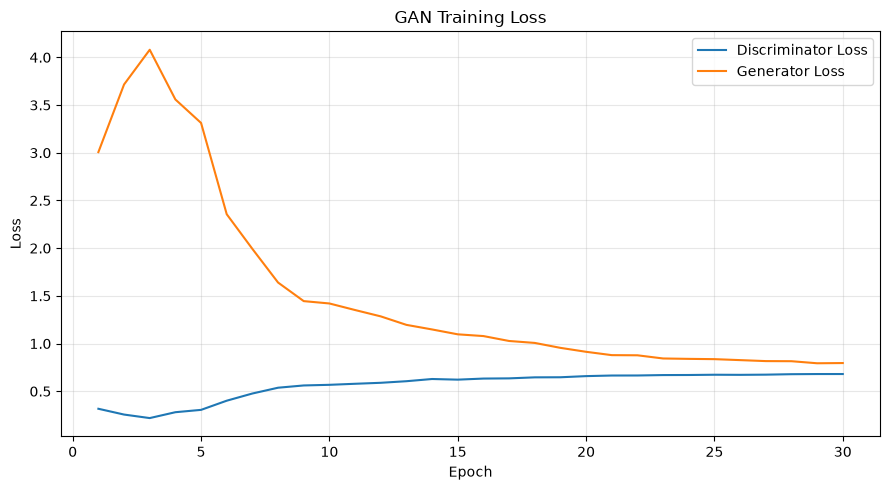

In [52]:

import matplotlib.pyplot as plt

epochs = range(1, len(loss_D_history) + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    loss_D_history,
    label="Discriminator Loss"
)

plt.plot(
    epochs,
    loss_G_history,
    label="Generator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


- 확실히 초반 부분에는 생성자가 학습을 잘 못해서 판별자가 진짜, 가짜 구분을 잘함
- 에폭이 늘수록 생성자가 학습을 잘해서 판별자가 구분하기가 힘듬
- 그래서 생산자 로스는 점점 줄고, 판별자 로스는 점점 증가함

## 생산 이미지 시각화

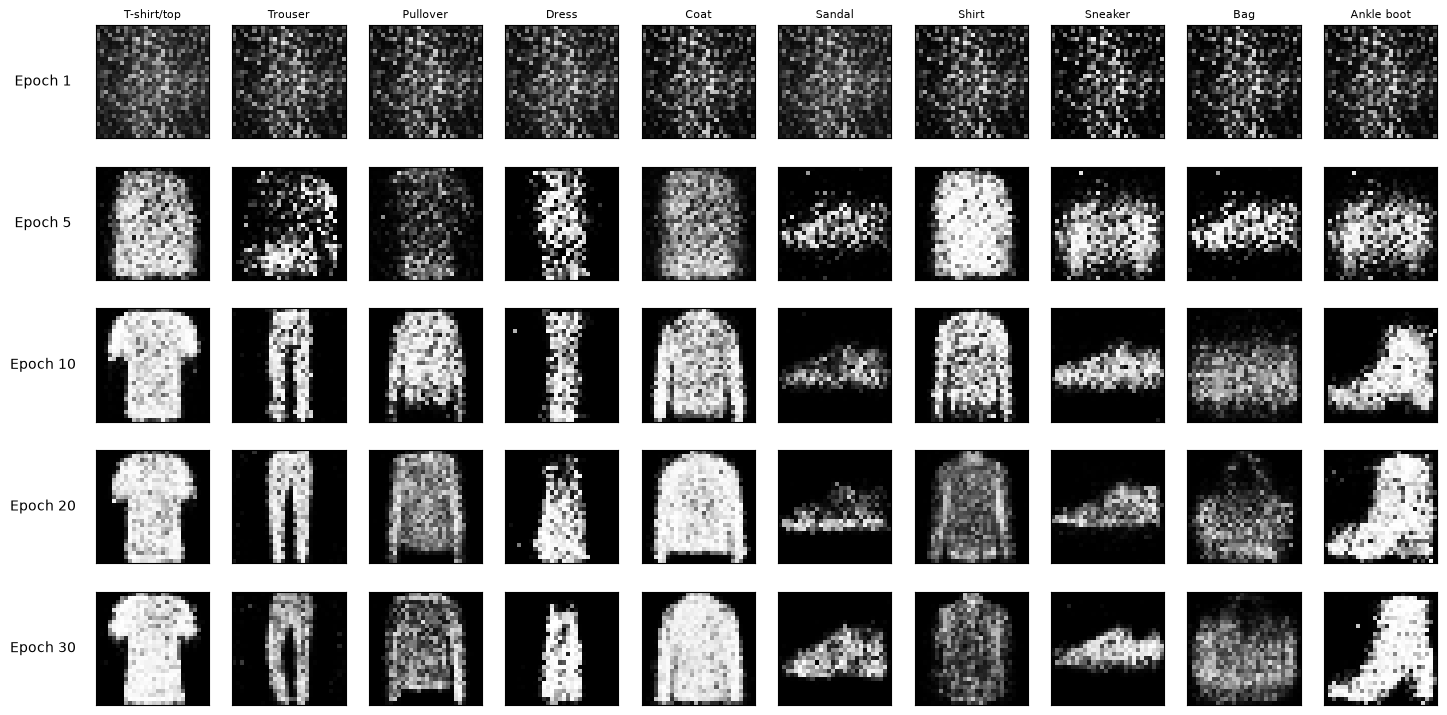

In [53]:

import matplotlib.pyplot as plt

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

compare_epochs = [1, 5, 10, 20, 30]

fig, axes = plt.subplots(
    nrows=len(compare_epochs),
    ncols=10,
    figsize=(15, 8)
)

# 이미지 사이 여백 설정
fig.subplots_adjust(
    left=0.09,
    right=0.99,
    top=0.91,
    bottom=0.06,
    wspace=0.12,
    hspace=0.25
)

for row, epoch in enumerate(compare_epochs):

    images = generated_images_by_epoch[epoch]

    for col in range(10):

        image = images[col].squeeze()

        # 픽셀 범위를 -1~1에서 0~1로 복원
        image = (image + 1) / 2

        axes[row, col].imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

        # 맨 위에 클래스 이름 표시
        if row == 0:
            axes[row, col].set_title(
                class_names[col],
                fontsize=8,
                pad=5
            )

        # 왼쪽에 에포크 표시
        if col == 0:
            axes[row, col].set_ylabel(
                f"Epoch {epoch}",
                fontsize=10,
                rotation=0,
                labelpad=38,
                va="center"
            )

plt.show()


- 보니까 1~5 에폭 사이에 판별자가 구분을 왜 잘했는지 알거같음
- 가면 갈수록 생산 이미지가 뚜렸해짐 구분하기 힘들거같음
- 클래스마다 각자 특징이 있음
- 원본과 비교했을때 내 눈으로 봤을때 구분하기 힘든것도 있음 (7, 8번 정도)

In [ ]:
평가지표

In [ ]:
생성 이미지 시각화	이미지가 실제 옷처럼 보이는지 확인	필수
클래스 조건 일치 여부	지정한 라벨에 맞는 옷이 생성되는지 확인	필수
FID	실제 이미지와 생성 이미지의 특징 분포 비교	추천
다양성 평가	비슷한 이미지만 반복해서 생성하는지 확인	추천
생성자·판별자 Loss	학습 과정의 변화와 불안정성 확인	필수
IS (Inception Score)	생성 이미지의 클래스 구분 가능성과 다양성을 간접 평가	선택